In [1]:
!pip install -q --no-cache-dir --force-reinstall --no-deps git+https://github.com/RayenSansa03/aeroguard.git@main

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
from google.colab import drive
drive.mount("/content/drive")

import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aeroguard.autoencodeurs import standardiser, statistiques_features
from aeroguard.donnees_ml import preparer_xy
from aeroguard.gan import DIM_BRUIT, creer_discriminateur, creer_generateur, entrainer_gan, generer

DOSSIER = "/content/drive/MyDrive/aeroguard"
FAMILLE_CIBLE = "fan"

vols = pd.read_parquet(f"{DOSSIER}/data/processed/vols_ncmapss.parquet")
X_train, y_train = preparer_xy(vols, "train")
medianes = X_train.median()                       # imputation des NaN avec les médianes du TRAIN
famille_train = vols.loc[X_train.index, "famille"].astype(str).to_numpy()

cible = (famille_train == FAMILLE_CIBLE) & (np.asarray(y_train) == 1)
X_cible = X_train[cible].fillna(medianes)
colonnes = list(X_cible.columns)
print(f"Vols usés « {FAMILLE_CIBLE} » dans le train : {len(X_cible)} vols × {len(colonnes)} features")

# Standardisation avec les statistiques des VRAIS vols ciblés (gardées pour revenir aux unités réelles)
moyennes, ecarts = statistiques_features(X_cible.to_numpy(dtype="float64"))
ecarts = np.where(np.asarray(ecarts) > 0, ecarts, 1.0)
X_reel = standardiser(X_cible.to_numpy(dtype="float64"), moyennes, ecarts).astype("float32")
print(f"Après standardisation : moyenne {X_reel.mean():.3f}, écart-type {X_reel.std():.3f}")

Mounted at /content/drive
Vols usés « fan » dans le train : 340 vols × 126 features
Après standardisation : moyenne 0.000, écart-type 1.000


In [3]:
generateur = creer_generateur(nombre_features=X_reel.shape[1])
discriminateur = creer_discriminateur(nombre_features=X_reel.shape[1])
generateur.summary()
discriminateur.summary()

Model: "generateur"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cachee_1 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (LeakyReLU)        │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cachee_2 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (LeakyReLU)        │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ faux_vol (Dense)                │ (None, 126)            │        16,254 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,686 (104.24 KB)

 Trainable params: 26,686 (104.24 KB)

 Non-trainable params: 0 (0.00 B)

Model: "discriminateur"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ cachee_1 (Dense)                │ (None, 128)            │        16,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (LeakyReLU)        │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cachee_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (LeakyReLU)        │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ logit_vrai (Dense)              │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,577 (96.00 KB)

 Trainable params: 24,577 (96.00 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
EPOCHS, TAILLE_LOT, TAUX = 2000, 64, 2e-4

debut = time.perf_counter()
historique = entrainer_gan(generateur, discriminateur, X_reel, epochs=EPOCHS, taille_lot=TAILLE_LOT,
                           taux_apprentissage=TAUX, afficher_tous_les=200)
duree = time.perf_counter() - debut
print(f"\nEntraînement terminé en {duree:.0f} s")

epoch   200 | perte D 1.341 | perte G 0.968 | D(vrais) 0.54 | D(faux) 0.41
epoch   400 | perte D 1.250 | perte G 0.885 | D(vrais) 0.55 | D(faux) 0.43
epoch   600 | perte D 1.229 | perte G 0.939 | D(vrais) 0.56 | D(faux) 0.41
epoch   800 | perte D 1.183 | perte G 0.947 | D(vrais) 0.57 | D(faux) 0.41
epoch  1000 | perte D 1.257 | perte G 0.986 | D(vrais) 0.55 | D(faux) 0.39
epoch  1200 | perte D 1.205 | perte G 0.899 | D(vrais) 0.57 | D(faux) 0.43
epoch  1400 | perte D 1.147 | perte G 0.951 | D(vrais) 0.57 | D(faux) 0.41
epoch  1600 | perte D 1.194 | perte G 0.925 | D(vrais) 0.59 | D(faux) 0.42
epoch  1800 | perte D 1.122 | perte G 1.036 | D(vrais) 0.58 | D(faux) 0.38
epoch  2000 | perte D 1.155 | perte G 0.968 | D(vrais) 0.58 | D(faux) 0.41

Entraînement terminé en 49 s


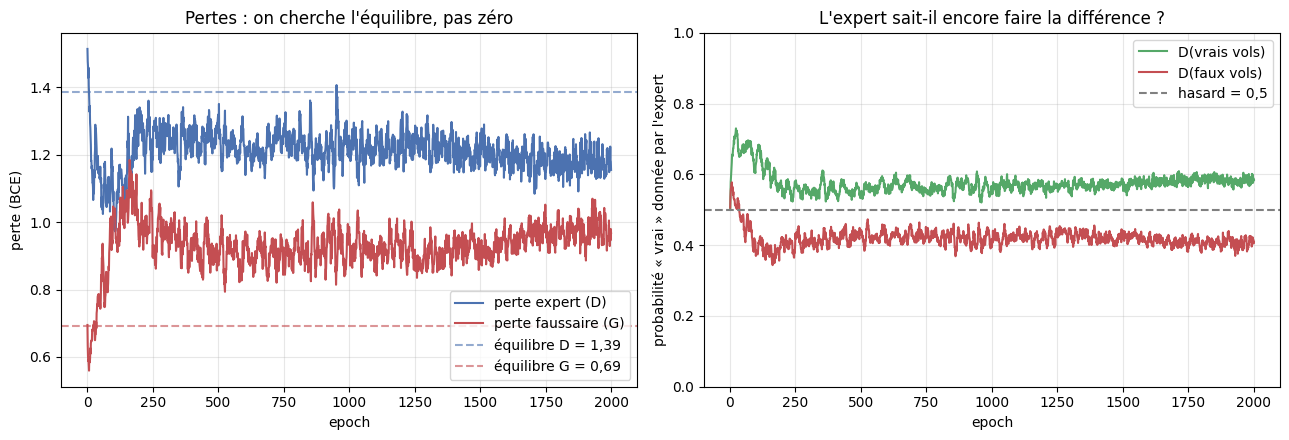

Moyennes sur les 100 dernières epochs : {'perte_d': 1.184, 'perte_g': 0.975, 'proba_vrais': 0.581, 'proba_faux': 0.408}


In [5]:
epochs = np.arange(1, EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(epochs, historique["perte_d"], label="perte expert (D)", color="#4C72B0")
ax1.plot(epochs, historique["perte_g"], label="perte faussaire (G)", color="#C44E52")
ax1.axhline(2 * np.log(2), color="#4C72B0", linestyle="--", alpha=0.6, label="équilibre D = 1,39")
ax1.axhline(np.log(2), color="#C44E52", linestyle="--", alpha=0.6, label="équilibre G = 0,69")
ax1.set_xlabel("epoch")
ax1.set_ylabel("perte (BCE)")
ax1.set_title("Pertes : on cherche l'équilibre, pas zéro")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(epochs, historique["proba_vrais"], label="D(vrais vols)", color="#55A868")
ax2.plot(epochs, historique["proba_faux"], label="D(faux vols)", color="#C44E52")
ax2.axhline(0.5, color="gray", linestyle="--", label="hasard = 0,5")
ax2.set_xlabel("epoch")
ax2.set_ylabel("probabilité « vrai » donnée par l'expert")
ax2.set_ylim(0, 1)
ax2.set_title("L'expert sait-il encore faire la différence ?")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{DOSSIER}/results/figures/62_entrainement_gan.png", dpi=150, bbox_inches="tight")
plt.show()

fin = {cle: round(float(np.mean(valeurs[-100:])), 3) for cle, valeurs in historique.items()}
print("Moyennes sur les 100 dernières epochs :", fin)

In [6]:
X_faux = generer(generateur, len(X_reel), graine=0)

# Espace standardisé : un bon faussaire donne des moyennes ≈ 0 et des écarts-types ≈ 1
ecart_moyennes = np.abs(X_faux.mean(axis=0) - X_reel.mean(axis=0)).mean()
rapport_ecarts = (X_faux.std(axis=0) / X_reel.std(axis=0).clip(min=1e-8)).mean()
print(f"Écart moyen des moyennes (standardisé) : {ecart_moyennes:.3f}  (idéal : proche de 0)")
print(f"Rapport moyen des écarts-types faux/vrais : {rapport_ecarts:.2f}  (idéal : proche de 1)")

# Retour aux unités réelles pour les capteurs clés du module 5
faux_reels = pd.DataFrame(X_faux * ecarts + moyennes, columns=colonnes)
capteurs_cles = [c for c in colonnes if c.split("_")[0] in {"P21", "P15", "P24", "T48", "T50"}][:8]
if not capteurs_cles:
    capteurs_cles = colonnes[:8]
comparaison = pd.DataFrame({
    "moyenne_vrais": X_cible[capteurs_cles].mean(),
    "moyenne_faux": faux_reels[capteurs_cles].mean(),
    "ecart_type_vrais": X_cible[capteurs_cles].std(),
    "ecart_type_faux": faux_reels[capteurs_cles].std(),
})
comparaison.round(3)

Écart moyen des moyennes (standardisé) : 0.145  (idéal : proche de 0)
Rapport moyen des écarts-types faux/vrais : 0.82  (idéal : proche de 1)


,moyenne_vrais,moyenne_faux,ecart_type_vrais,ecart_type_faux
T48_mean_montee,-1.793,-1.931,6.787,5.964
T48_mean_croisiere,-2.497,-3.193,6.291,3.901
T48_mean_descente,-0.974,-1.400,4.340,4.580
T48_std_montee,1.217,1.092,0.324,0.264
T48_std_croisiere,1.781,1.682,0.681,0.421
T48_std_descente,2.986,2.862,0.713,0.557
T48_max_montee,3.439,3.428,6.812,3.781
T48_max_croisiere,10.598,5.304,15.495,6.770


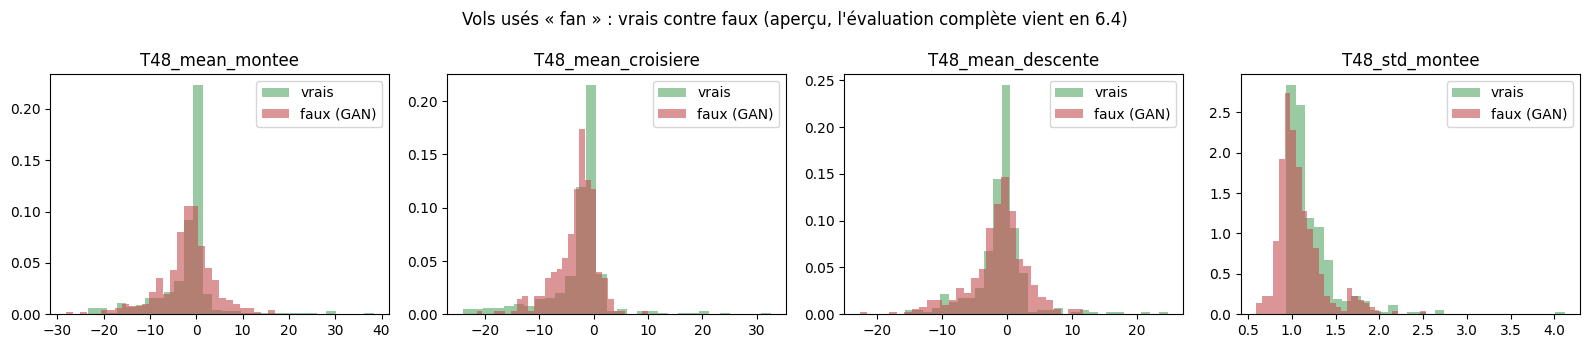

In [7]:
a_tracer = capteurs_cles[:4]
fig, axes = plt.subplots(1, len(a_tracer), figsize=(4 * len(a_tracer), 3.5))
for axe, colonne in zip(np.atleast_1d(axes), a_tracer):
    axe.hist(X_cible[colonne], bins=30, alpha=0.6, density=True, label="vrais", color="#55A868")
    axe.hist(faux_reels[colonne], bins=30, alpha=0.6, density=True, label="faux (GAN)", color="#C44E52")
    axe.set_title(colonne)
    axe.legend()
plt.suptitle(f"Vols usés « {FAMILLE_CIBLE} » : vrais contre faux (aperçu, l'évaluation complète vient en 6.4)")
plt.tight_layout()
plt.savefig(f"{DOSSIER}/results/figures/62_apercu_faux_vols.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
generateur.save(f"{DOSSIER}/models/gan_fan_v6_generateur.keras")
np.savez(f"{DOSSIER}/models/gan_fan_v6_stats.npz", moyennes=moyennes, ecarts=ecarts,
         medianes_imputation=medianes.to_numpy(), colonnes=np.array(colonnes, dtype=str))
config = {"famille": FAMILLE_CIBLE, "vols_reels": int(len(X_reel)), "dim_bruit": DIM_BRUIT,
          "epochs": EPOCHS, "taille_lot": TAILLE_LOT, "taux_apprentissage": TAUX,
          "duree_s": round(duree), "fin_entrainement": fin,
          "ecart_moyennes": round(float(ecart_moyennes), 3), "rapport_ecarts": round(float(rapport_ecarts), 3)}
with open(f"{DOSSIER}/models/gan_fan_v6_config.json", "w") as f:
    json.dump(config, f, indent=2)
print("✅ Générateur sauvegardé :", config)

✅ Générateur sauvegardé : {'famille': 'fan', 'vols_reels': 340, 'dim_bruit': 32, 'epochs': 2000, 'taille_lot': 64, 'taux_apprentissage': 0.0002, 'duree_s': 49, 'fin_entrainement': {'perte_d': 1.184, 'perte_g': 0.975, 'proba_vrais': 0.581, 'proba_faux': 0.408}, 'ecart_moyennes': 0.145, 'rapport_ecarts': 0.817}
